In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

In [2]:
%run 00.ipynb

c:\Users\SafinSharma\miniconda3\envs\forecasting\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Export Folder : standardized_exports
Results Folder: results
24
Datasets Found: 22
agri_medium
agri_small
energy_medium
energy_small
favorita-train_medium
favorita-train_medium_cov
favorita-train_small
favorita-train_small_cov
favorita-transaction_medium
favorita-transaction_small
m4-daily_medium
m4-daily_small
m4-hourly_medium
m4-hourly_small
m4-quarterly_medium
m4-quarterly_small
m4-weekly_medium
m4-weekly_small
m4-yearly_medium
m4-yearly_small
traffic_medium
traffic_small
5
agri_medium               rows=15343      series=246      horizon=5
5
agri_small                rows=14428      series=246      horizon=5
24
energy_medium             rows=177600     series=370      horizon=24
24
energy_small              rows=44400      series=370      horizon=24
28
favorita-train_medium     rows=1985155    series=4504     horizon=28
favorita-train_medium_cov -> ERROR: No horizon configured for favorita-train_medium_cov
28
favorita-train_small      rows=609961     series=4504     horizon=28
favo

In [3]:
COVARIATE_FOLDER = Path(
    "favorita_covariates"
)

holiday_df = pd.read_csv(
    COVARIATE_FOLDER /
    "holidays_events.csv"
)

items_df = pd.read_csv(
    COVARIATE_FOLDER /
    "items.csv"
)

oil_df = pd.read_csv(
    COVARIATE_FOLDER /
    "oil.csv"
)

stores_df = pd.read_csv(
    COVARIATE_FOLDER /
    "stores.csv"
)

In [4]:
holiday_df["date"] = pd.to_datetime(
    holiday_df["date"]
)

oil_df["date"] = pd.to_datetime(
    oil_df["date"]
)

In [5]:
def build_favorita_covariates(df):

    df = df.copy()

    df["store_nbr"] = (
        df["unique_id"]
        .str.split("_")
        .str[0]
        .astype(int)
    )

    df["item_nbr"] = (
        df["unique_id"]
        .str.split("_")
        .str[1]
        .astype(int)
    )

    df["ds"] = pd.to_datetime(
        df["ds"]
    )

    # ---------------------
    # Date Features
    # ---------------------

    df["year"] = df["ds"].dt.year
    df["month"] = df["ds"].dt.month
    df["day"] = df["ds"].dt.day
    df["weekday"] = df["ds"].dt.dayofweek

    df["weekend"] = (
        df["weekday"] >= 5
    ).astype(int)

    # ---------------------
    # Oil
    # ---------------------

    oil = oil_df.rename(
        columns={
            "date":"ds"
        }
    )

    oil["dcoilwtico"] = (
        oil["dcoilwtico"]
        .ffill()
        .bfill()
    )

    df = df.merge(
        oil,
        on="ds",
        how="left"
    )

    # ---------------------
    # Holidays
    # ---------------------

    holiday = holiday_df.rename(
        columns={
            "date":"ds"
        }
    )

    holiday["is_holiday"] = 1

    df = df.merge(

        holiday[
            [
                "ds",
                "is_holiday"
            ]
        ].drop_duplicates(),

        on="ds",

        how="left"
    )

    df["is_holiday"] = (
        df["is_holiday"]
        .fillna(0)
    )

    # ---------------------
    # Store Metadata
    # ---------------------

    df = df.merge(

        stores_df,

        on="store_nbr",

        how="left"
    )

    # ---------------------
    # Item Metadata
    # ---------------------

    df = df.merge(

        items_df,

        on="item_nbr",

        how="left"
    )

    return df

In [6]:
favorita_files = [

    "favorita-train_small",
    "favorita-train_medium"
]

In [7]:
for dataset in favorita_files:

    print(dataset)

    df = pd.read_csv(
        EXPORT_FOLDER /
        f"{dataset}.csv"
    )

    df = build_favorita_covariates(
        df
    )
    
    df["dcoilwtico"] = (
    df["dcoilwtico"]
    .ffill()
    .bfill()
)

    output_file = (
        EXPORT_FOLDER /
        f"{dataset}_cov.csv"
    )

    df.to_csv(
        output_file,
        index=False
    )

    print(
        "Saved:",
        output_file
    )

favorita-train_small
Saved: standardized_exports\favorita-train_small_cov.csv
favorita-train_medium
Saved: standardized_exports\favorita-train_medium_cov.csv


In [8]:
from sklearn.preprocessing import LabelEncoder

In [9]:
def encode_categories(df):

    df = df.copy()

    for col in [
        "family",
        "city",
        "state",
        "type"
    ]:

        if col in df.columns:

            encoder = LabelEncoder()

            df[col] = encoder.fit_transform(
                df[col]
                .astype(str)
            )

    return df

In [10]:
feature_columns = [

    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",

    "rolling_mean_3",

    "onpromotion",

    "dcoilwtico",

    "is_holiday",

    "perishable",

    "cluster",

    "weekday",

    "month",

    "family",

    "city",

    "state",

    "type"
]

In [11]:
DATASET = "favorita-train_medium"

df = pd.read_csv(
    EXPORT_FOLDER /
    f"{DATASET}_cov.csv"
)

df = encode_categories(df)

df["ds"] = pd.to_datetime(df["ds"])

print(df.shape)

df.head()

(1985155, 20)


,unique_id,ds,y,onpromotion,store_nbr,item_nbr,year,month,day,weekday,weekend,dcoilwtico,is_holiday,city,state,type,cluster,family,class,perishable
0,10_1001305,2014-11-28,2.0,False,10,1001305,2014,11,28,4,0,65.94,1.0,1,0,1,15,11,1016,0
1,10_1001305,2014-11-29,2.0,False,10,1001305,2014,11,29,5,1,65.94,0.0,1,0,1,15,11,1016,0
2,10_1001305,2014-11-30,7.0,False,10,1001305,2014,11,30,6,1,65.94,0.0,1,0,1,15,11,1016,0
3,10_1001305,2014-12-01,1.0,False,10,1001305,2014,12,1,0,0,68.98,1.0,1,0,1,15,11,1016,0
4,10_1001305,2014-12-02,3.0,False,10,1001305,2014,12,2,1,0,66.99,0.0,1,0,1,15,11,1016,0


In [12]:
def create_features(df):

    df = df.copy()

    lag_features = []

    for lag in [1, 2, 3, 7]:

        col = f"lag_{lag}"

        df[col] = (
            df
            .groupby("unique_id")["y"]
            .shift(lag)
        )

        lag_features.append(col)

    df["rolling_mean_3"] = (
        df
        .groupby("unique_id")["y"]
        .shift(1)
        .rolling(3)
        .mean()
    )

    return df

In [13]:
df = create_features(df)

df = df.dropna(
    subset=[
        "lag_1",
        "lag_2",
        "lag_3",
        "lag_7",
        "rolling_mean_3"
    ]
).reset_index(drop=True)

print(df.columns.tolist())

['unique_id', 'ds', 'y', 'onpromotion', 'store_nbr', 'item_nbr', 'year', 'month', 'day', 'weekday', 'weekend', 'dcoilwtico', 'is_holiday', 'city', 'state', 'type', 'cluster', 'family', 'class', 'perishable', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'rolling_mean_3']


In [14]:
horizon = get_horizon(DATASET)

train_parts = []
test_parts = []

for uid in df["unique_id"].unique():

    series = df[
        df["unique_id"] == uid
    ].sort_values("ds")

    train_parts.append(
        series.iloc[:-horizon]
    )

    test_parts.append(
        series.iloc[-horizon:]
    )

train_df = pd.concat(
    train_parts,
    ignore_index=True
)

test_df = pd.concat(
    test_parts,
    ignore_index=True
)

print(train_df.shape)
print(test_df.shape)

(1827515, 25)
(126112, 25)


In [15]:
baseline_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "rolling_mean_3"
]

In [16]:
print(df.columns.tolist())

['unique_id', 'ds', 'y', 'onpromotion', 'store_nbr', 'item_nbr', 'year', 'month', 'day', 'weekday', 'weekend', 'dcoilwtico', 'is_holiday', 'city', 'state', 'type', 'cluster', 'family', 'class', 'perishable', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'rolling_mean_3']


In [17]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

baseline_model = LGBMRegressor(
    random_state=42
)

baseline_model.fit(
    train_df[baseline_features],
    train_df["y"]
)

baseline_preds = baseline_model.predict(
    test_df[baseline_features]
)

baseline_mae = mean_absolute_error(
    test_df["y"],
    baseline_preds
)

print(
    "Baseline MAE:",
    round(baseline_mae, 4)
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.057570 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1275
[LightGBM] [Info] Number of data points in the train set: 1827515, number of used features: 5
[LightGBM] [Info] Start training from score 6.694119
Baseline MAE: 3.1355


In [18]:
covariate_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "rolling_mean_3",
    "onpromotion",
    "dcoilwtico",
    "weekday",
    "month",
    "family",
]


In [19]:
for frame in [train_df, test_df]:

    frame["onpromotion"] = (
        frame["onpromotion"]
        .replace({
            True: 1,
            False: 0,
            "True": 1,
            "False": 0,
            "true": 1,
            "false": 0
        })
        .fillna(0)
        .astype(int)
    )

In [20]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

all_family = pd.concat(
    [
        train_df["family"],
        test_df["family"]
    ]
).astype(str)

encoder.fit(all_family)

train_df["family"] = encoder.transform(
    train_df["family"].astype(str)
)

test_df["family"] = encoder.transform(
    test_df["family"].astype(str)
)

In [21]:
cov_model = LGBMRegressor(
    random_state=42
)

cov_model.fit(
    train_df[covariate_features],
    train_df["y"]
)

cov_preds = cov_model.predict(
    test_df[covariate_features]
)

cov_mae = mean_absolute_error(
    test_df["y"],
    cov_preds
)

print(
    "Covariate MAE:",
    round(cov_mae, 4)
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.034500 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1584
[LightGBM] [Info] Number of data points in the train set: 1827515, number of used features: 10
[LightGBM] [Info] Start training from score 6.694119
Covariate MAE: 3.1353


In [22]:
improvement = (
    (
        baseline_mae -
        cov_mae
    )
    / baseline_mae
) * 100

print(
    f"Improvement: {improvement:.2f}%"
)

Improvement: 0.00%


In [23]:
importance = pd.DataFrame(
    {
        "feature": covariate_features,
        "importance": cov_model.feature_importances_
    }
)

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,feature,importance
0,lag_1,483
3,lag_7,479
1,lag_2,366
6,dcoilwtico,334
2,lag_3,329
7,weekday,292
4,rolling_mean_3,271
9,family,191
8,month,141
5,onpromotion,114


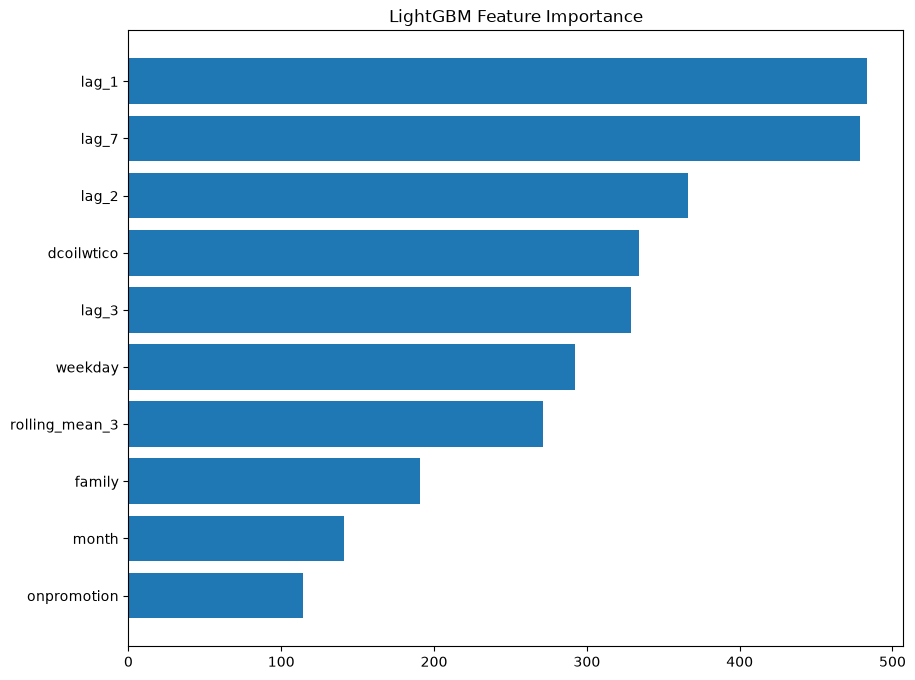

In [24]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(10,8)
)

plt.barh(
    importance["feature"][:20],
    importance["importance"][:20]
)

plt.title(
    "LightGBM Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

In [25]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

xgb_model.fit(
    train_df[covariate_features],
    train_df["y"]
)

xgb_preds = xgb_model.predict(
    test_df[covariate_features]
)

xgb_mae = mean_absolute_error(
    test_df["y"],
    xgb_preds
)

print("XGBoost MAE:", xgb_mae)

XGBoost MAE: 3.126215207970867


In [26]:
ml_results = pd.DataFrame(
    {
        "Model": [
            "LightGBM",
            "XGBoost"
        ],
        "MAE": [
            cov_mae,
            xgb_mae
        ]
    }
)

ml_results.sort_values("MAE")

,Model,MAE
1,XGBoost,3.126215
0,LightGBM,3.135344


In [27]:
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS

In [28]:
hist_exog = [
    "onpromotion",
    "dcoilwtico",
    "is_holiday"
]

train_nf = train_df[
    [
        "unique_id",
        "ds",
        "y",
        *hist_exog
    ]
].copy()

test_nf = test_df[
    [
        "unique_id",
        "ds",
        *hist_exog
    ]
].copy()

In [29]:
test_nf["dcoilwtico"].isna().sum()

0

In [30]:
nhits = NHITS(
    h=horizon,
    input_size=21,
    max_steps=50,
    hist_exog_list=hist_exog
)

nf = NeuralForecast(
    models=[nhits],
    freq="D"
)
for frame in [train_nf, test_nf]:

    frame["dcoilwtico"] = (
        frame["dcoilwtico"]
        .ffill()
        .bfill()
    )
nf.fit(train_nf)

Seed set to 1
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MAE           │      0 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm  │      0 │ train │     0 │
│ 6 │ blocks              │ ModuleList    │  2.5 M │ train │     0 │
└───┴─────────────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 2.5 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.5 M                                                                                                
Total estimated model params size (MB): 10.044                                                                     
Modules in train mode: 37                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_steps=50` reached.


In [31]:
future_df = nf.make_future_dataframe()

covs = test_nf.copy()

future_df = future_df.merge(
    covs,
    on=["unique_id", "ds"],
    how="left"
)

future_df["onpromotion"] = future_df["onpromotion"].fillna(0)

future_df["is_holiday"] = future_df["is_holiday"].fillna(0)

future_df["dcoilwtico"] = (
    future_df["dcoilwtico"]
    .ffill()
    .bfill()
)

In [32]:
nhits_preds = nf.predict()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

In [33]:
nhits_eval = test_df[
    [
        "unique_id",
        "ds",
        "y"
    ]
].merge(
    nhits_preds,
    on=["unique_id","ds"]
)

nhits_mae = mean_absolute_error(
    nhits_eval["y"],
    nhits_eval["NHITS"]
)

print(
    "NHITS MAE:",
    round(nhits_mae,4)
)

NHITS MAE: 4.0554


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from sklearn.preprocessing import StandardScaler

In [35]:
lstm_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "rolling_mean_3",
    "onpromotion",
    "dcoilwtico",
    "is_holiday",
    "weekday",
    "month"
]

In [36]:
x_scaler = StandardScaler()

X_train = x_scaler.fit_transform(
    train_df[lstm_features]
)

X_test = x_scaler.transform(
    test_df[lstm_features]
)

y_train = train_df["y"].values
y_test = test_df["y"].values

In [37]:
X_train = X_train.reshape(
    X_train.shape[0],
    1,
    X_train.shape[1]
)

X_test = X_test.reshape(
    X_test.shape[0],
    1,
    X_test.shape[1]
)

In [38]:
lstm_model = Sequential(
    [
        LSTM(
            64,
            activation="tanh"
        ),
        Dense(32),
        Dense(1)
    ]
)

In [39]:
lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

In [40]:
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 58s 8ms/step - loss: 136.8519 - val_loss: 102.6092
Epoch 2/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 42s 6ms/step - loss: 134.2141 - val_loss: 102.6998
Epoch 3/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 36s 6ms/step - loss: 133.9008 - val_loss: 103.6208
Epoch 4/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 37s 6ms/step - loss: 133.6386 - val_loss: 102.0463
Epoch 5/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 36s 6ms/step - loss: 133.5601 - val_loss: 101.7615
Epoch 6/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 40s 6ms/step - loss: 133.4250 - val_loss: 100.5871
Epoch 7/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 37s 6ms/step - loss: 133.2330 - val_loss: 103.5608
Epoch 8/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - loss: 133.1373 - val_loss: 101.5785
Epoch 9/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - loss: 133.0830 - val_loss: 103.0140
Epoch 10/10
6425/6425 ━━━━━━━━━━━━━━━━━━━━ 44s 6ms/step - loss: 133.0063 - val_loss: 103.3189


In [41]:
lstm_preds = (
    lstm_model
    .predict(X_test)
    .flatten()
)

3941/3941 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step


In [42]:
train_df[lstm_features].isna().sum().sort_values(ascending=False)

lag_1             0
lag_2             0
lag_3             0
lag_7             0
rolling_mean_3    0
onpromotion       0
dcoilwtico        0
is_holiday        0
weekday           0
month             0
dtype: int64

In [43]:
lstm_mae = mean_absolute_error(
    y_test,
    lstm_preds
)

print(
    "LSTM MAE:",
    round(lstm_mae,4)
)

LSTM MAE: 3.1008


In [44]:
results = pd.DataFrame(
    {
        "Model":[
            "LightGBM",
            "XGBoost",
            "NHITS",
            "LSTM"
        ],
        "MAE":[
            cov_mae,
            xgb_mae,
            nhits_mae,
            lstm_mae
        ]
    }
)

results = results.sort_values(
    "MAE"
)

results

,Model,MAE
3,LSTM,3.100792
1,XGBoost,3.126215
0,LightGBM,3.135344
2,NHITS,4.055415


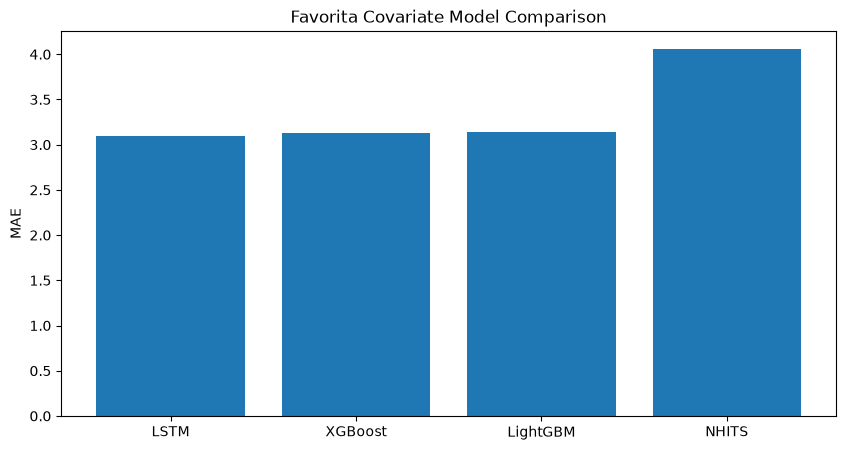

In [45]:
plt.figure(
    figsize=(10,5)
)

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.title(
    "Favorita Covariate Model Comparison"
)

plt.ylabel(
    "MAE"
)

plt.show()

In [46]:
results.to_csv(
    "results/favorita_covariate_model_results.csv",
    index=False
)

print(
    "Saved favorita_covariate_model_results.csv"
)

Saved favorita_covariate_model_results.csv


In [47]:
covariates = [
    "onpromotion",
    "dcoilwtico",
    "is_holiday"
]

ttm_train = train_df[
    [
        "unique_id",
        "ds",
        "y",
        *covariates
    ]
].copy()

ttm_test = test_df[
    [
        "unique_id",
        "ds",
        "y",
        *covariates
    ]
].copy()


In [48]:
for df_ in [ttm_train, ttm_test]:

    df_["onpromotion"] = (
        df_["onpromotion"]
        .fillna(0)
        .astype(float)
    )

    df_["is_holiday"] = (
        df_["is_holiday"]
        .fillna(0)
        .astype(float)
    )

    df_["dcoilwtico"] = (
        df_["dcoilwtico"]
        .ffill()
        .bfill()
    )

In [49]:
import tsfm_public
import transformers

print(tsfm_public.__version__)
print(transformers.__version__)

0.2.9
4.46.3


In [50]:
from tsfm_public import TinyTimeMixerForPrediction
from tsfm_public.toolkit.dataset import ForecastDFDataset

INFO:p-15056:t-19356:config.py:<module>:TensorFlow version 2.21.0 available.


In [51]:
train_dataset = ForecastDFDataset(
    data=ttm_train,
    id_columns=["unique_id"],
    timestamp_column="ds",
    target_columns=["y"],
    observable_columns=covariates,
    context_length=64,
    prediction_length=horizon
)

test_dataset = ForecastDFDataset(
    data=ttm_test,
    id_columns=["unique_id"],
    timestamp_column="ds",
    target_columns=["y"],
    observable_columns=covariates,
    context_length=64,
    prediction_length=horizon
)

In [52]:
from transformers import Trainer
from transformers import TrainingArguments

model = TinyTimeMixerForPrediction.from_pretrained(
    "ibm-research/ttm-r3"
)


Some weights of TinyTimeMixerForPrediction were not initialized from the model checkpoint at ibm-research/ttm-r3 and are newly initialized: ['backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.gating_block.attn_layer.bias', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.gating_block.attn_layer.weight', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.mlp.fc1.bias', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.mlp.fc1.weight', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.mlp.fc2.bias', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.mlp.fc2.weight', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.norm.norm.bias', 'backbone.encoder.mlp_mixer_encoder.mixers.0.feature_mixer.norm.norm.weight', 'backbone.encoder.mlp_mixer_encoder.mixers.0.patch_mixer.gating_block.attn_layer.bias', 'backbone.encoder.mlp_mixer_encoder.mixers.0.patch_mixer.gating_block.attn_layer.weight', 'backbone.encoder.mlp_mixer_encoder.mixers.0

In [ ]:
training_args = TrainingArguments(
    output_dir="./ttm_favorita",
    num_train_epochs=5,
    per_device_train_batch_size=32,
    learning_rate=1e-4,
    logging_steps=50,
    save_strategy="no"
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset
)
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice:wandb: Enter your choice

In [ ]:
preds = trainer.predict(
    test_dataset
)

ttm_preds = preds.predictions.squeeze()

In [ ]:
from sklearn.metrics import mean_absolute_error

y_true = (
    ttm_test["y"]
    .values[:len(ttm_preds)]
)

ttm_mae = mean_absolute_error(
    y_true,
    ttm_preds
)

print(
    "TTM Covariate MAE:",
    round(ttm_mae, 4)
)

In [ ]:
import transformers

try:
    import granite_tsfm
except:
    pass

try:
    import tsfm_public
    print("tsfm_public:", tsfm_public.__version__)
except:
    print("tsfm_public not found")

print("transformers:", transformers.__version__)

tsfm_public: 0.2.9
transformers: 5.14.1
